# Creating and saving the synthetic dataset

In [1]:
# Parameters
NUM_SAMPLES = 200
MIN_LENGTH = 5
MAX_LENGTH = 10
SIGNAL_FREQUENCY = 1
SAMPLING_FREQUENCY = 100
NOISE = 0.10
HISTORY_DIR = 'history'

Generate a synthetic dataset and save each shot as an HDF5 file in the reference state's `history/` folder:

In [3]:
import os
from random import randint

from make_dataset import generate_signal
from tsmadkit.io import write_hdf5_input_data

# Generate the dataset
sample_sizes = [randint(MIN_LENGTH, MAX_LENGTH) for _ in range(NUM_SAMPLES)]
dataset = [generate_signal(size, SIGNAL_FREQUENCY, SAMPLING_FREQUENCY, NOISE) for size in sample_sizes]

# Save the dataset
if not os.path.exists(HISTORY_DIR):
   os.makedirs(HISTORY_DIR)
for i, shot in enumerate(dataset):
   write_hdf5_input_data(f'{HISTORY_DIR}/shot_{i:03}.h5', shot)

# TSM pipeline

The following will be performed in C++ in the main TSM POZ app, either in pure C++ or by calling Python classes from the code.

## Anomaly detection

Instantiate the algorithm and call `setup()`. This prepares the algorithm's reference state by reading the shots from `history/`, extracting TSFEL features for each one (via `transform()`), and caching them for comparison at detection time:

In [4]:
from algorithm import DummyClusteringAnomalyDetection

# Instantiate the anomaly detection algorithm with its proper configuration
intershot_detection = DummyClusteringAnomalyDetection("config.json")

# Prepare the reference state (history + cache) from the shots saved above
intershot_detection.setup()

Create a new "*normal*" shot on which to perform anomaly detection:

In [5]:
from tsmadkit.signals import SignalSet

normal_shot = generate_signal(8, SIGNAL_FREQUENCY, SAMPLING_FREQUENCY, NOISE)
normal_data = SignalSet(normal_shot, intershot_detection.signal_spec)

# Run the anomaly detection on this new normal shot
result = intershot_detection.detect(normal_data)
print(result)

is_anomaly=False scores={'dbscan_isolation_score': 0.5988690396164699} label=None time_min=None time_max=None sources=None details=None message=None


Create a new anomalous shot (with increased noise level) on which to perform anomaly detection:

In [6]:
# Create an anomalous shot (increased noise)
anomalous_shot = generate_signal(8, SIGNAL_FREQUENCY, SAMPLING_FREQUENCY, NOISE+0.1)
anomalous_data = SignalSet(anomalous_shot, intershot_detection.signal_spec)

# Run again using an anomalous shot
result = intershot_detection.detect(anomalous_data)
print("Anomalous:", result)

Anomalous: is_anomaly=True scores={'dbscan_isolation_score': 4.39781513767959} label=None time_min=None time_max=None sources=None details=None message=None


Plot all the historical shots (from the reference state), the recently created normal shot and the recently created anomalous shot:

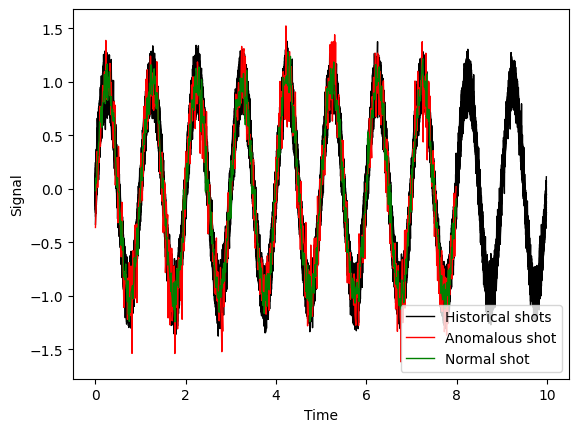

In [7]:
import matplotlib.pyplot as plt

# Plot all the shots from the reference state's history
for shot in intershot_detection.reference_state.history.data.values():
    plt.plot(shot.time, shot["sensor_0"], c='k', lw=1, label='Historical shots')

# Plotting anomalous and normal shots
plt.plot(anomalous_data.time, anomalous_data["sensor_0"], lw=1, c='r', label='Anomalous shot')
plt.plot(normal_data.time, normal_data["sensor_0"], lw=1, c='g', label='Normal shot')

plt.xlabel("Time")
plt.ylabel("Signal")
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())
plt.show()